# 01 · CSIC 2010 baseline (TF-IDF + Logistic Regression)

الهدف: نحمّل CSIC 2010، ننضفها، ونطلع أول موديل يفرّق بين الطلب العادي والهجمة.

هنجرب نسختين من النص:
- **full**: الـ Method + الـ URL + الـ body (كل اللي في CSIC)
- **log**: الـ Method + الـ URL بس، يعني اللي بيظهر فعلاً في الـ access log بتاع Nginx. دي اللي هنقارن بيها في تجربة التعميم.

In [1]:
from pathlib import Path
from urllib.parse import unquote_plus
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

# الـ notebook جوه notebooks/، فالداتا فولدر لفوق
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
RAW = ROOT / 'data' / 'raw' / 'csic_database.csv'
OUT = ROOT / 'data' / 'processed'
OUT.mkdir(parents=True, exist_ok=True)
RAW

WindowsPath('c:/Users/ms182/Downloads/AI PROJECT/AI-ATTACK-INVESTIGATOR/data/raw/csic_database.csv')

## 1. تحميل وتنضيف

- العمود `Unnamed: 0` فيه Normal/Anomalous، و`classification` فيه 0/1. هنتأكد إنهم متطابقين ونستخدم `classification` كـ label.
- نشيل ` HTTP/1.1` من آخر الـ URL، ونشيل `http://localhost:8080` من أوله، عشان الـ access log بيسجل الـ path بس.
- نعمل URL-decode عشان الموديل يشوف الحروف الحقيقية.

In [2]:
df = pd.read_csv(RAW)
df = df.rename(columns={'Unnamed: 0': 'label_text', 'classification': 'label', 'lenght': 'length'})
print(df.shape)
print(pd.crosstab(df['label_text'], df['label']))

(61065, 17)
label           0      1
label_text              
Anomalous       0  25065
Normal      36000      0


In [3]:
def clean_url(u):
    u = str(u)
    if u.endswith(' HTTP/1.1'):
        u = u[:-len(' HTTP/1.1')]
    u = u.replace('http://localhost:8080', '', 1)
    return u

def decode(s):
    return unquote_plus(str(s), encoding='latin-1')

df['path'] = df['URL'].map(clean_url)
df['body'] = df['content'].fillna('')
df['text_log'] = df['Method'] + ' ' + df['path'].map(decode)
df['text_full'] = df['text_log'] + ' ' + df['body'].map(decode)
df[['Method', 'path', 'body', 'label']].head()

,Method,path,body,label
0,GET,/tienda1/index.jsp,,0
1,GET,/tienda1/publico/anadir.jsp?id=3&nombre=Vino+R...,,0
2,POST,/tienda1/publico/anadir.jsp,id=3&nombre=Vino+Rioja&precio=100&cantidad=55&...,0
3,GET,/tienda1/publico/autenticar.jsp?modo=entrar&lo...,,0
4,POST,/tienda1/publico/autenticar.jsp,modo=entrar&login=choong&pwd=d1se3ci%F3n&remem...,0


## 2. نظرة سريعة

In [4]:
print(df['label'].value_counts(normalize=True).round(3))
print(df.groupby('Method')['label'].agg(['count', 'mean']).round(3))
dups = df.duplicated(subset=['text_full']).sum()
conflict = df.groupby('text_full')['label'].nunique().gt(1).sum()
print(f'duplicate requests: {dups}, same text with both labels: {conflict}')

label
0    0.59
1    0.41
Name: proportion, dtype: float64
        count   mean
Method              
GET     43088  0.350
POST    17580  0.545
PUT       397  1.000
duplicate requests: 35457, same text with both labels: 0


**ملحوظة:** لو فيه طلبات متكررة، ممكن نفس الطلب ييجي في الـ train والـ test فالنتيجة تطلع أعلى من الحقيقة. عشان كده هنشيل التكرار قبل التقسيم، ونشيل الطلبات اللي ليها الـ label الاتنين.

In [5]:
conflict_texts = df.groupby('text_full')['label'].nunique().loc[lambda s: s > 1].index
clean = df[~df['text_full'].isin(conflict_texts)].drop_duplicates(subset=['text_full']).reset_index(drop=True)
print(len(df), '->', len(clean))
print(clean['label'].value_counts())
clean[['Method', 'path', 'body', 'text_log', 'text_full', 'label']].to_csv(OUT / 'csic_clean.csv', index=False)

61065 -> 25608
label
1    15964
0     9644
Name: count, dtype: int64


## 3. Baseline

TF-IDF على حروف (character n-grams من 2 لـ 4)، لأن الـ URL مش كلام عادي ومفيهوش مسافات. و`class_weight='balanced'` عشان الكلاسين مش متساويين.

In [6]:
train_df, test_df = train_test_split(clean, test_size=0.2, stratify=clean['label'], random_state=42)

def baseline():
    return make_pipeline(
        TfidfVectorizer(analyzer='char', ngram_range=(2, 4), min_df=2, max_features=100_000, sublinear_tf=True),
        LogisticRegression(max_iter=2000, class_weight='balanced'),
    )

models, results = {}, {}
for col in ['text_full', 'text_log']:
    m = baseline().fit(train_df[col], train_df['label'])
    pred = m.predict(test_df[col])
    models[col] = m
    results[col] = f1_score(test_df['label'], pred)
    print(f'===== {col} =====')
    print(classification_report(test_df['label'], pred, target_names=['Normal', 'Anomalous'], digits=3))

pd.Series(results, name='F1 (Anomalous)').round(3)

===== text_full =====
              precision    recall  f1-score   support

      Normal      0.889     0.995     0.939      1929
   Anomalous      0.997     0.925     0.959      3193

    accuracy                          0.951      5122
   macro avg      0.943     0.960     0.949      5122
weighted avg      0.956     0.951     0.952      5122

===== text_log =====
              precision    recall  f1-score   support

      Normal      0.538     0.994     0.698      1929
   Anomalous      0.993     0.484     0.651      3193

    accuracy                          0.676      5122
   macro avg      0.766     0.739     0.675      5122
weighted avg      0.822     0.676     0.669      5122



text_full    0.959
text_log     0.651
Name: F1 (Anomalous), dtype: float64

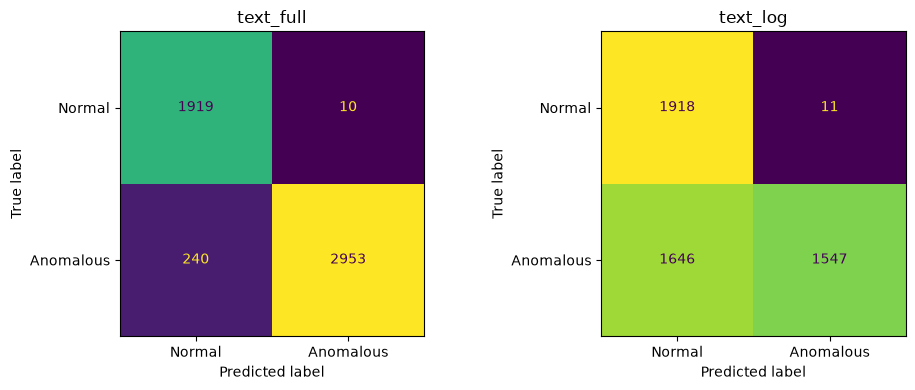

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, models):
    ConfusionMatrixDisplay.from_estimator(models[col], test_df[col], test_df['label'],
                                          display_labels=['Normal', 'Anomalous'], ax=ax, colorbar=False)
    ax.set_title(col)
plt.tight_layout()

## 4. الموديل بيبص على إيه؟

أكتر n-grams بتشد ناحية Anomalous وناحية Normal (موديل `text_log`).

In [8]:
vec, lr = models['text_log'].named_steps.values()
coef = pd.Series(lr.coef_[0], index=vec.get_feature_names_out())
pd.DataFrame({'anomalous': coef.nlargest(20).index, 'normal': coef.nsmallest(20).index})

,anomalous,normal
0,a=,d=
1,r/,n=
2,mar/,o=
3,/&,&b1=
4,ar/,b1=
5,a/,1=
6,ja/,do=
7,aja/,odo=
8,da=,gin=
9,oa=,in=


## 5. اكتب هنا اللي لاحظته

- F1 للـ full كام، وللـ log كام؟ الفرق ده معناه قد إيه بنخسر لما نشتغل على الـ access log بس.
- طلبات POST: في نسخة log الـ body مش موجود، فالهجمات اللي في الـ body مش هتبان. ده لازم يتكتب في التقرير.
- الخطوة الجاية (أسبوع 3): مقارنة LR وRF وXGBoost، وcross-validation.